# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [30]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

# Feature Engineering
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,silhouette_samples ,adjusted_rand_score
from scipy.cluster import hierarchy
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score


In [5]:
# Load data  
# Load data
df_Avg = pd.read_csv("avg_river_levels.csv")
df_Min = pd.read_csv("min_river_levels.csv")
df_Max = pd.read_csv("max_river_levels.csv")
df_Locs = pd.read_csv("monitoring_locations.csv", index_col="Observation_ID")
#df_Avg.head()
#df_Min.head()
#df_Max.head()
#df_Locs.head()

# check dates 
Dates = pd.to_datetime( df_Avg.columns[3:], format="%d/%m/%Y" )
print("Date col. ", len(Dates))
print("Days in the period:", (Dates.max() - Dates.min()).days + 1)
all_days = pd.date_range(Dates.min(), Dates.max(), freq="D")
print(all_days.difference(Dates))

Date col.  4379
Days in the period: 4387
DatetimeIndex(['2014-10-11', '2014-10-12', '2014-11-26', '2015-04-17',
               '2015-04-22', '2015-05-03', '2015-05-26', '2016-04-06'],
              dtype='datetime64[us]', freq=None)


In [6]:

def to_daily(df):
    #Takes data frame from one of the river level files
    #Returns the water levels wirth one row per day and one column per station
    
    levels= df.iloc[:, 3:].T
    levels.index = pd.to_datetime(levels.index, format="%d/%m/%Y")
    levels.columns = df["Observation_ID"]
    
    return levels


# Re-shap dates 
avg= to_daily(df_Avg)
lo= to_daily(df_Min)
hi= to_daily(df_Max)

# Avrage, minimum and maximum value in each file 
pd.DataFrame({"avg":[ avg.min().min(), avg.max().max() ], 
             "min":[ lo.min().min(), lo.max().max() ], 
             "max":[ hi.min().min(), hi.max().max()] },index=[ "smallest" , "largest" ])



    

,avg,min,max
smallest,-190475.436,-999999.999,-29.638
largest,999999.999,999999.999,999999.999


# Introduction

This report looks at the water levels taken at 392 monitoring stations across Scotland
throughout the day from October 2014 to October 2026 and asks what stations have similar
behaviour. The level data at each station is provided as three time series: average, minimum
and maximum level, in metres above the gauge datum, all provided on a daily basis. From the
records, it is known that the stations differ in just about every aspect of which monitoring is concerned.

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

**My notes**

 
-Removed the 24 sea gauges, because they measure the tide not a river. 
-removed outliers based on IQR*20 because the water levels can be more than IQR*3. Removed 91 station-days at 23 stations
-error codes 999999 were removed.
-There is a bar plot that sjow the data covarage and years before 2023 are missing more that 80% of thier data.
-stations with data on fewer than 80% of thoes days were dropped. 343 stations left.

stations after removing sea gause 368


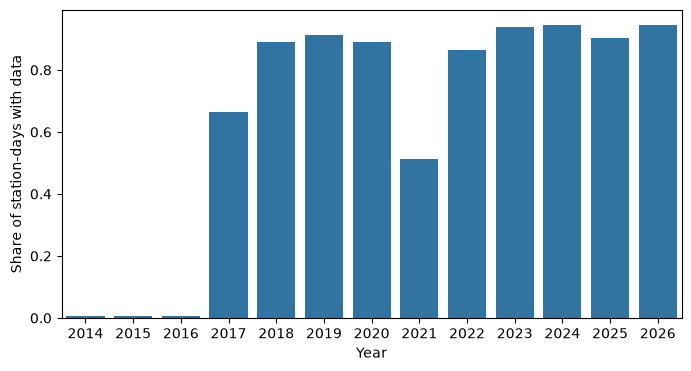

Stations:  343 , days:  1377
Missing values left: 0.022
(343, 1377)


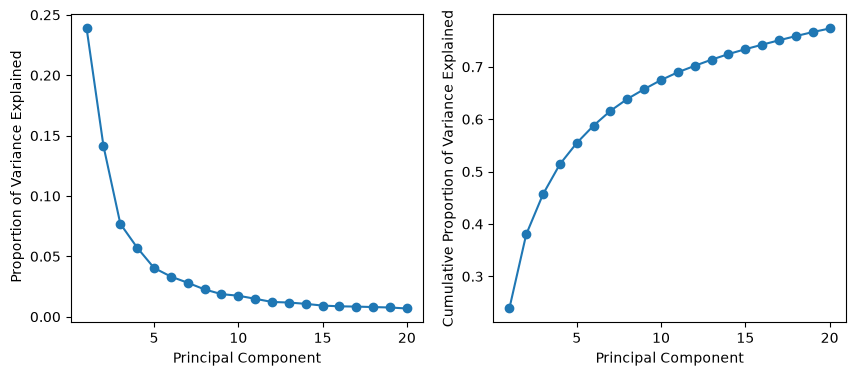

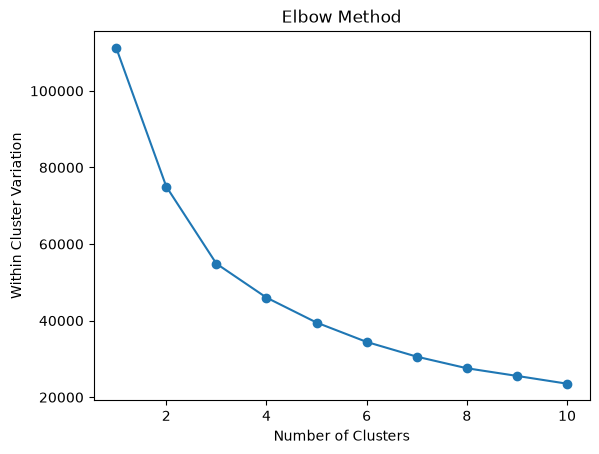

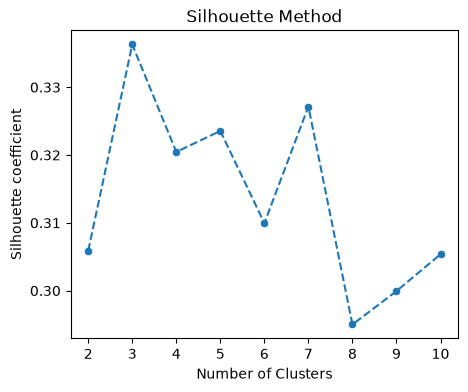

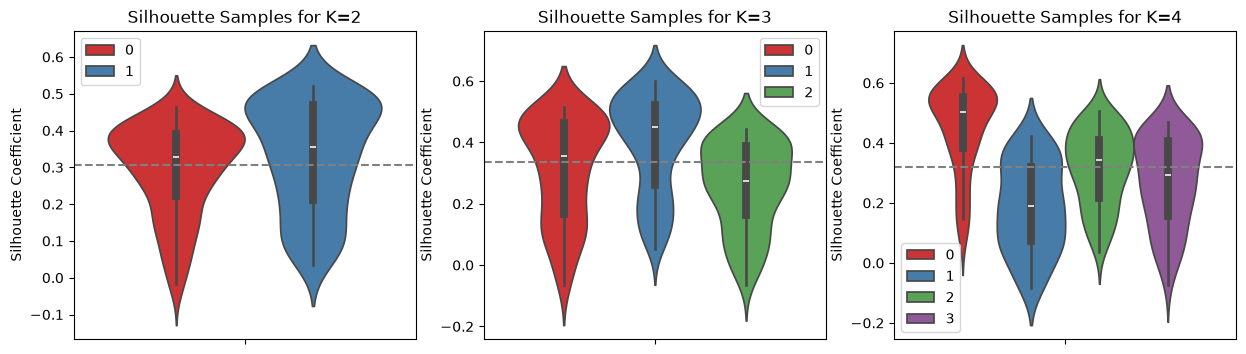

0    109
1    148
2     86
Name: count, dtype: int64
0    165
1     80
2     98
Name: count, dtype: int64
0    165
1     80
2     98
Name: count, dtype: int64
K-Means: 0.336
Hierarchical: 0.318
Adjusted Rand Index: 0.649


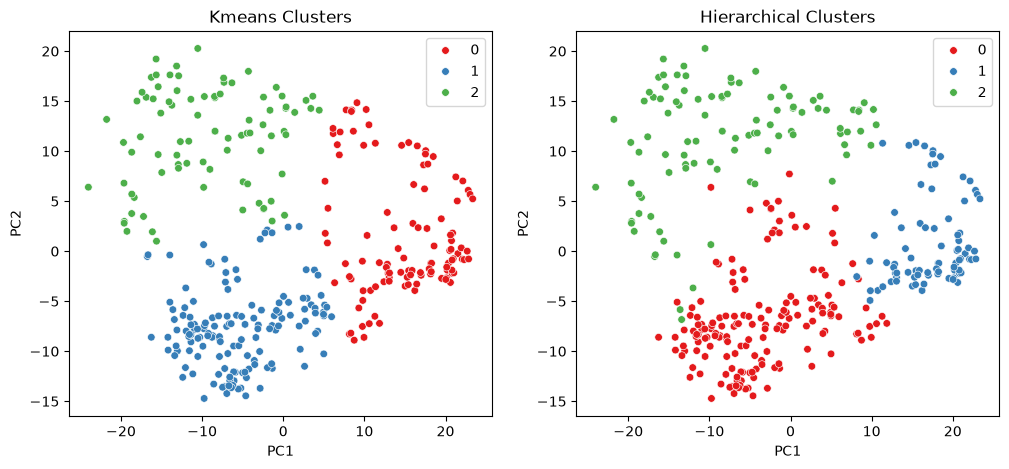

            P1     P2    P3    P4    P5
Cluster                                
0        14.81   1.49 -0.48 -1.36 -0.31
1        -5.46  -7.69  0.21  0.48  0.61
2        -9.38  11.35  0.24  0.89 -0.66


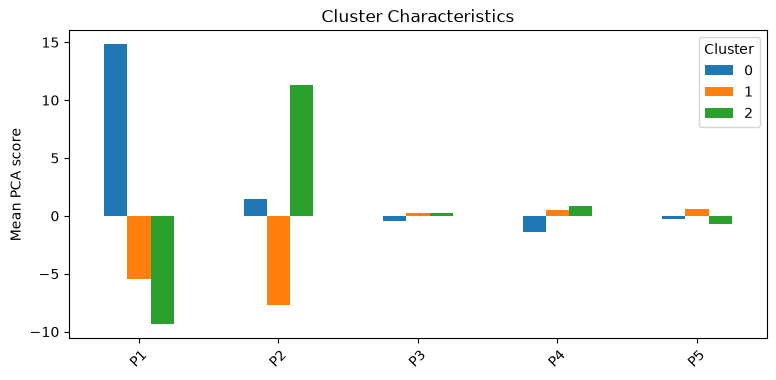

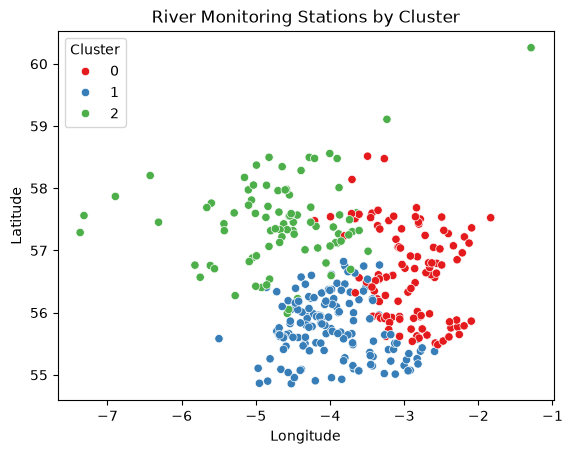

In [43]:
#EDA and data cleaning

# Treat error codes "99999.999, -999999.999 and -99" as missing values
error_Code =(avg.abs() >=9999)|(lo.abs() >=9999)|(hi.abs() >=9999)|(lo == -99)

#print("There are {} station-days with error codes in {} stations".format(error_code.sum().sum(), error_code.any().sum()))
# Replace the error codes with missing values (NAN) 
#We remove the same amount of days from all data files so the calculations stay consistant
avg[error_Code]= np.nan
lo[error_Code]= np.nan
hi[error_Code]= np.nan


#Get the station name with tide level to remove them (Sea data)
tidal_sites= df_Avg.loc[ df_Avg["Observation_ID"].str.contains("tidal-level"), "Station_Name" ] 
coastal= pd.Series(df_Avg["Station_Name"].isin(tidal_sites).values, index=df_Avg["Observation_ID"])
avg= avg.loc[:,~avg.columns.isin(coastal[coastal].index)]
print("stations after removing sea gause", avg.shape[1])

#Remove outliers where thier values lies way outside its IQR *20 to be realistic
#Tukey fence for each statoin
q1=avg.quantile(0.25)    
q3=avg.quantile(0.75)
iqr=q3-q1

# scaled = (avg - avg.median()) / iqr
# extreme = scaled.abs().max().sort_values(ascending=False).index[:6]

#Plot the 6 stations with most extreme values 
# fig, ax = plt.subplots(1, 1, figsize=(10, 4))
# sns.boxplot(data=scaled[extreme].rename(columns=df_Locs["Station_Name"]), orient="h", whis=20, ax=ax)
# ax.set_xscale("symlog")
# ax.set_xlabel("(level-median) / IQR")
# plt.show()

# Based on the box plot results we choose k=20
k= 20
outlier= avg.gt(q3 + k * iqr) | avg.lt(q1 - k * iqr)
avg[outlier] =np.nan
lo[outlier] =np.nan
hi[outlier] =np.nan

# Take station days with data only (by year)
coverage_Year = avg.notna().groupby(avg.index.year).mean().mean(axis=1)

fig,ax = plt.subplots(1,1,figsize=(8,4))
sns.barplot(x=coverage_Year.index,y=coverage_Year.values,ax=ax)
ax.set_xlabel("Year")
ax.set_ylabel("Share of station-days with data")
plt.show()

# Use data from 2023 (the year where data has most covarage)
# Years befor 2023 has less then 90% covarage 
period = avg.loc["2023-01-01":]

#Keep stations with data at least %80 of these days #Week1
covarage = period.notna().mean()
period = period.loc[:,covarage >= 0.8]
print("Stations: ",period.shape[1], ", days: ",period.shape[0] )
print("Missing values left:",round(period.isna().mean().mean(),3))

#Standarise each column/station
scaler= StandardScaler()
period_std = scaler.fit_transform(period)
x_days= period_std.T                     #Rows=Stations and Columns=Days

# Fill missing data with the median of that day
num_imputer = SimpleImputer(strategy="median")
x_days = num_imputer.fit_transform(x_days)
print(x_days.shape)

#PCA for the clustering part
# Zoom in on first 20 componants
max_comp = 20 
pca = PCA().fit(x_days)

fig,ax= plt.subplots( 1, 2, figsize= (10,4) )
ticks= np.arange( max_comp ) + 1
ax[0].plot( ticks, pca.explained_variance_ratio_[range( max_comp )] , marker='o' )
ax[0].set_xlabel( 'Principal Component' )
ax[0].set_ylabel(' Proportion of Variance Explained' )
ax[1].plot( ticks, pca.explained_variance_ratio_[range( max_comp )].cumsum() , marker='o' )
ax[1].set_xlabel( 'Principal Component' )
ax[1].set_ylabel( 'Cumulative Proportion of Variance Explained' )
plt.show()

#print(sum(pca.explained_variance_ratio_[range(5)]))
# Keep 5 componants - elbow
pca_5n = PCA(n_components =5).fit(x_days) 
score = pca_5n.transform(x_days)


# Try different numbers of clusters
K = np.arange(1, 11)
WCV = np.zeros(K.shape)

# Calculate within-cluster variation
for i in range(len(K)):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(score)
    WCV[i] = kmeans_K.inertia_

# Plot the elbow method
plt.plot(K, WCV, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Within Cluster Variation')
plt.title('Elbow Method')
plt.show()


# Trying different numbers of clusters
K = np.array([2,3,4,5,6,7,8,9,10])
sil_coef = np.zeros(K.shape)
# Calculate silhouette scores
for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20 , random_state=0).fit(score)
    labs= kmeans_K.predict(score)
    sil_coef[i] = silhouette_score(score,labs)
#print(dict(zip(K, sil_coef.round(3))))


# Plot the scores
fig,ax = plt.subplots(1,1,figsize = (5,4))
sns.lineplot(x=K,y=sil_coef,linestyle='dashed', ax=ax)
sns.scatterplot(x=K, y=sil_coef, ax=ax)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette coefficient')
plt.title('Silhouette Method')
plt.show()

# silhouette samples for K= 2,3,4
fig,ax = plt.subplots(1,3,figsize = (15,4))
for i in range (3):
    kmeans_K = KMeans(n_clusters= K[i], n_init=20 , random_state=0).fit(score)
    labs= kmeans_K.predict(score)
    sil_samp = silhouette_samples(score,labs)
    sns.violinplot(y=sil_samp,hue=labs,ax=ax[i],palette='Set1')
    ax[i].axhline(sil_samp.mean(),ls='--',c="gray")
    ax[i].set_title(f'Silhouette Samples for K={K[i]}')
    ax[i].set_ylabel('Silhouette Coefficient')
plt.show()


# Fit K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, n_init=20, random_state=0)
labels = kmeans.fit_predict(score)

# Number of stations in each cluster
print(pd.Series(labels).value_counts().sort_index())

# Fit hierarchecal clustering with 3 clusters
hc = AgglomerativeClustering(n_clusters=3)
hc_labels = hc.fit_predict(score)
print(pd.Series(hc_labels).value_counts().sort_index())


# Count stations in each cluster
print(pd.Series(hc_labels).value_counts().sort_index())

# Compair the clustering methods 
print("K-Means:",round(silhouette_score(score,labels),3))
print("Hierarchical:",round(silhouette_score(score,hc_labels),3))
# Compare cluster assignments
print("Adjusted Rand Index:",round(adjusted_rand_score(labels, hc_labels),3))


# Plot the clusters in PCA
fig2 ,ax= plt.subplots(1,2,figsize=(12,5))
sns.scatterplot(x=score[:,0], y=score[:, 1],hue=labels, palette='Set1',s=30,ax=ax[0])
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[0].set_title('Kmeans Clusters')
sns.scatterplot(x=score[:, 0], y=score[:,1],hue=hc_labels, palette='Set1',s=30,ax=ax[1])
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].set_title('Hierarchical Clusters')
plt.show()

# Compare cluseters on the PCA components
cluster_Z = pd.DataFrame(score, columns=["P1","P2","P3","P4","P5"])
cluster_Z["Cluster"] = labels
print(cluster_Z.groupby("Cluster").mean().round(2))

cluster_Z.groupby("Cluster").mean().T.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Mean PCA score")
plt.title("Cluster Characteristics")
plt.xticks(rotation=45)
plt.show()

# Add labels to station locations
Locations = df_Locs.loc[period.columns].copy()
Locations["Cluster"]= labels


# Average location and main counties of each cluster
# print(locations.groupby("Cluster")[["Latitude","Longitude"]].mean().round(2))
# for c in range(3):
#     print("Cluster",c,locations.loc[locations["Cluster"] == c,"County"].value_counts().head(5).to_dict())


# Plot stations by cluster
sns.scatterplot(data=Locations, x="Longitude", y="Latitude",
                hue="Cluster", palette="Set1")

plt.title("River Monitoring Stations by Cluster")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()




# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

ELM: 
How is pd.to_datetime used. 

# References

*Include a list of all references cited in the text.*

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
